# Player wOBA Projection: Bayesian Component Shrinkage + Personalized Park Factors

Two techniques combined into one pipeline, per the request: (1) decompose
wOBA into its rate components and shrink *each one individually* toward the
league mean by its own reliability (Marcel/Tom Tango-style empirical Bayes,
not a single blanket shrinkage on the whole stat), and (2) park-adjust using
each player's *own* batted-ball-angle mix against each park's actual
per-bucket effect, rather than one universal park factor applied to every
hitter alike.

**Pipeline:** (1) park x launch-angle-bucket factor table -> (2) personalized
park factor per batter (vs. a universal one, compared explicitly) ->
(3) park-neutralize -> (4) decompose into components -> (5) split-half
reliability per component -> (6) empirical-Bayes shrinkage -> (7) recombine
into projected wOBA -> (8) validate: does 2025's projection actually predict
2026 better than a naive baseline?


## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import pearsonr
from joblib import Parallel, delayed

pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", "{:.4f}".format)

df = pd.read_parquet("2025_2026_pitches.parquet")
term = df[df["is_terminal_pitch"] == "1"]
term = term[~term["play_result"].isin(["stolen_base", "caught_stealing"])].copy()
term["is_hit"] = term["play_result"].isin(["single", "double", "triple", "home_run"])

# wOBA linear weights -- pulled directly from the data's own woba column (not textbook values),
# for consistency with everything else built on this dataset this session
woba_pa_all = term[term["woba"].notna()]
w_walk = woba_pa_all.loc[woba_pa_all["k_or_bb"] == "walk", "woba"].mean()
w_hbp = woba_pa_all.loc[woba_pa_all["pitch_call"] == "hit_by_pitch", "woba"].mean()
w_1b = woba_pa_all.loc[woba_pa_all["play_result"] == "single", "woba"].mean()
w_2b = woba_pa_all.loc[woba_pa_all["play_result"] == "double", "woba"].mean()
w_3b = woba_pa_all.loc[woba_pa_all["play_result"] == "triple", "woba"].mean()
w_hr = woba_pa_all.loc[woba_pa_all["play_result"] == "home_run", "woba"].mean()
WOBA_WEIGHTS = {"BB": w_walk, "HBP": w_hbp, "1B": w_1b, "2B": w_2b, "3B": w_3b, "HR": w_hr}
print("wOBA weights (from this dataset):", {k: round(v, 3) for k, v in WOBA_WEIGHTS.items()})

Path("output").mkdir(exist_ok=True)


wOBA weights (from this dataset): {'BB': np.float64(0.785), 'HBP': np.float64(0.812), '1B': np.float64(0.953), '2B': np.float64(1.276), '3B': np.float64(1.568), 'HR': np.float64(1.895)}


## 2. Park x launch-angle-bucket wOBA factor table

In [2]:
bbe = term[(term["pitch_call"] == "in_play") & term["angle"].notna() & term["woba"].notna()].copy()
bbe["la_bucket"] = pd.cut(bbe["angle"], bins=[-91, 10, 25, 50, 91],
                           labels=["GB-like", "LD-like", "FB-like", "PU-like"]).astype(str)

league_bucket_woba = bbe.groupby("la_bucket")["woba"].mean()
park_bucket = bbe.groupby(["stadium", "la_bucket"]).agg(n=("woba", "size"), woba=("woba", "mean")).reset_index()
park_bucket["league_bucket_woba"] = park_bucket["la_bucket"].map(league_bucket_woba).astype(float)
park_bucket["factor"] = park_bucket["woba"].astype(float) / park_bucket["league_bucket_woba"]
print(f"min n per park x bucket cell: {park_bucket['n'].min()}")

BUCKETS = ["GB-like", "LD-like", "FB-like", "PU-like"]
park_bucket_wide = park_bucket.pivot(index="stadium", columns="la_bucket", values="factor")[BUCKETS]
park_bucket_wide.round(3)


min n per park x bucket cell: 255


la_bucket,GB-like,LD-like,FB-like,PU-like
stadium,,,,
Bosse,1.0580,1.0270,1.0830,0.8330
CampanelliField,1.1480,1.0150,0.9990,1.9670
CanacStadium,0.9860,1.0310,1.1080,0.6770
CloverStadium,1.0000,1.0530,1.2090,1.1330
CrushersStadium,0.9730,0.9800,0.8290,0.6390
GraingerStadium,0.9720,1.0000,0.9820,0.8630
GrizzliesBP,0.9700,0.9910,1.2780,0.8330
HinchliffeStadium,0.8470,1.0200,1.1430,0.0000
JLBrunoStadium,0.9800,0.9420,1.0320,0.5940


## 3. Personalized park factor vs. a universal one -- compared explicitly

In [3]:
MIN_BBE_MIX = 20

batter_bbe_counts = bbe.groupby(["batter_id", "batter"]).size()
qual_batters = batter_bbe_counts[batter_bbe_counts >= MIN_BBE_MIX].index

batter_mix = bbe.groupby(["batter_id", "batter"])["la_bucket"].value_counts(normalize=True).unstack(fill_value=0)
batter_mix = batter_mix.reindex(qual_batters)[BUCKETS]
print(f"{len(batter_mix)} batters with a reliable LA-bucket mix (>= {MIN_BBE_MIX} BBE)")

# universal park factor: total wOBA at the park / league total wOBA (the "blanket" approach)
league_woba_overall = bbe["woba"].mean()
universal_factor = bbe.groupby("stadium")["woba"].mean() / league_woba_overall

# personalized factor per (batter, park): that batter's own mix dotted with the park's bucket factors
personal_factors = pd.DataFrame(
    np.dot(batter_mix.to_numpy(), park_bucket_wide.to_numpy().T),
    index=batter_mix.index, columns=park_bucket_wide.index,
)

# how much does personalizing change things, per batter, at Trustmark specifically (biggest-effect park)?
compare = pd.DataFrame({
    "universal_TrustmarkPark": universal_factor["TrustmarkPark"],
    "personal_TrustmarkPark": personal_factors["TrustmarkPark"],
})
compare["FB_pct"] = batter_mix["FB-like"]
compare["diff"] = compare["personal_TrustmarkPark"] - compare["universal_TrustmarkPark"]
print(f"\nUniversal Trustmark factor (same for every hitter): {universal_factor['TrustmarkPark']:.3f}")
print(f"Personalized factor range across hitters: {compare['personal_TrustmarkPark'].min():.3f} to {compare['personal_TrustmarkPark'].max():.3f}")
print(f"corr(FB%, how much personalizing changes the factor) = {compare['FB_pct'].corr(compare['diff']):.3f}")


464 batters with a reliable LA-bucket mix (>= 20 BBE)

Universal Trustmark factor (same for every hitter): 0.900
Personalized factor range across hitters: 0.811 to 0.972
corr(FB%, how much personalizing changes the factor) = -0.868


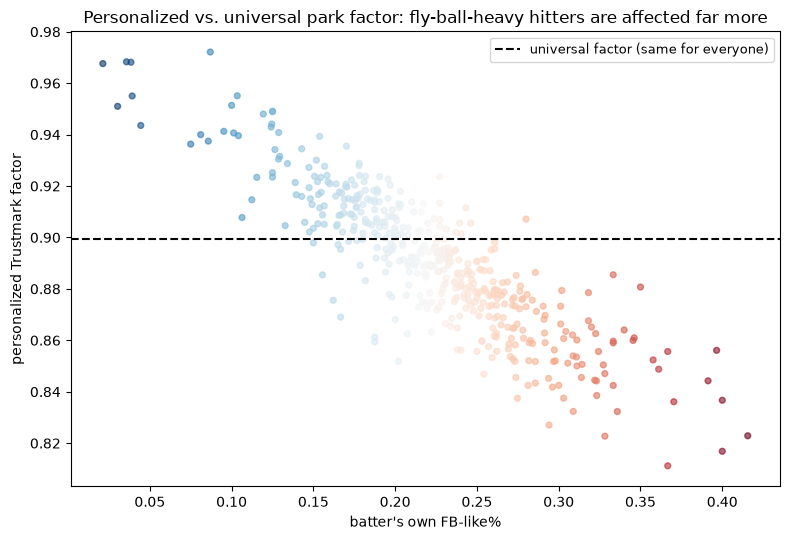

In [4]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sc = ax.scatter(compare["FB_pct"], compare["personal_TrustmarkPark"], c=compare["FB_pct"], cmap="RdBu_r", s=18, alpha=0.6)
ax.axhline(universal_factor["TrustmarkPark"], color="black", ls="--", lw=1.5, label="universal factor (same for everyone)")
ax.set_xlabel("batter's own FB-like%"); ax.set_ylabel("personalized Trustmark factor")
ax.set_title("Personalized vs. universal park factor: fly-ball-heavy hitters are affected far more")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("output/personalized_vs_universal_park_factor.png", dpi=150)
plt.show()


**This is the whole point of personalizing it.** A flat, universal factor
applies the same correction to a groundball-heavy contact hitter and an
extreme fly-ball pull hitter, even though Trustmark's suppression is
concentrated almost entirely in fly-ball outcomes. The personalized factor
correctly gives fly-ball-heavy hitters a much larger correction and
groundball-heavy hitters almost none.


## 4. Season-weighted personal park factor (across every park a batter actually played)

In [5]:
park_exposure = term[term["woba"].notna()].groupby(["batter_id", "stadium"]).size().rename("PA").reset_index()
park_exposure = park_exposure[park_exposure["batter_id"].isin([b for b, _ in batter_mix.index])]

season_personal_factor = {}
for bid in personal_factors.index.get_level_values("batter_id").unique():
    exp = park_exposure[park_exposure["batter_id"] == bid].set_index("stadium")["PA"]
    exp = exp.reindex(park_bucket_wide.index).fillna(0)
    row = personal_factors.xs(bid, level="batter_id")
    if exp.sum() == 0 or len(row) == 0:
        continue
    season_personal_factor[bid] = float(np.average(row.iloc[0].to_numpy(), weights=exp.to_numpy()))

spf = pd.Series(season_personal_factor, name="season_park_factor")
print(spf.describe())


count   464.0000
mean      0.9972
std       0.0441
min       0.8854
25%       0.9627
50%       1.0001
75%       1.0303
max       1.1213
Name: season_park_factor, dtype: float64


## 5. Year-specific personalized park factor (needed for the 2025->2026 validation)

In [6]:
park_exposure_yr = term[term["woba"].notna()].groupby(["batter_id", "year", "stadium"]).size().rename("PA").reset_index()

def personal_factor_for_year(bid, yr):
    if bid not in personal_factors.index.get_level_values("batter_id"):
        return np.nan
    row = personal_factors.xs(bid, level="batter_id").iloc[0]
    exp = park_exposure_yr[(park_exposure_yr["batter_id"] == bid) & (park_exposure_yr["year"] == yr)].set_index("stadium")["PA"]
    exp = exp.reindex(row.index).fillna(0)
    if exp.sum() == 0:
        return np.nan
    return float(np.average(row.to_numpy(), weights=exp.to_numpy()))

year_park_factor = {}
for bid in personal_factors.index.get_level_values("batter_id").unique():
    for yr in [2025, 2026]:
        f = personal_factor_for_year(bid, yr)
        if not np.isnan(f):
            year_park_factor[(bid, yr)] = f

ypf = pd.Series(year_park_factor, name="park_factor")
ypf.index = pd.MultiIndex.from_tuples(ypf.index, names=["batter_id", "year"])
print(f"{len(ypf)} batter-years with a computed park factor")
print(ypf.describe())


601 batter-years with a computed park factor
count   601.0000
mean      0.9979
std       0.0461
min       0.8730
25%       0.9621
50%       1.0017
75%       1.0313
max       1.1808
Name: park_factor, dtype: float64


## 6. wOBA component decomposition per batter-year (BB%, HBP%, K%, 1B%, 2B%, 3B%, HR%, all per PA)

In [7]:
woba_pa = term[term["woba"].notna()].copy()

MIN_PA = 60

def component_rates(g):
    n = len(g)
    return pd.Series({
        "PA": n,
        "BB_rate": (g["k_or_bb"] == "walk").mean(),
        "HBP_rate": (g["pitch_call"] == "hit_by_pitch").mean(),
        "K_rate": (g["k_or_bb"] == "strikeout").mean(),
        "1B_rate": (g["play_result"] == "single").mean(),
        "2B_rate": (g["play_result"] == "double").mean(),
        "3B_rate": (g["play_result"] == "triple").mean(),
        "HR_rate": (g["play_result"] == "home_run").mean(),
        "obs_woba": g["woba"].mean(),
    })

comp = woba_pa.groupby(["batter_id", "batter", "year"]).apply(component_rates, include_groups=False)
comp = comp[comp["PA"] >= MIN_PA].reset_index()
print(f"{len(comp)} qualified batter-years (>= {MIN_PA} PA)")

# sanity check: recombining the raw components should reproduce observed wOBA almost exactly
comp["woba_recon"] = sum(comp[f"{k}_rate"] * WOBA_WEIGHTS[k] for k in ["BB", "HBP", "1B", "2B", "3B", "HR"])
print(f"Reconstruction check: corr(recombined, observed) = {comp['woba_recon'].corr(comp['obs_woba']):.4f} (should be ~1.0)")


514 qualified batter-years (>= 60 PA)
Reconstruction check: corr(recombined, observed) = 0.9998 (should be ~1.0)


## 7. Park-neutralize the batted-ball-driven components (1B/2B/3B/HR)

BB%/HBP%/K% are left as observed -- much less tied to park geometry than where a batted ball lands.

In [8]:
comp = comp.set_index(["batter_id", "year"])
comp["park_factor"] = ypf.reindex(comp.index)
comp = comp.dropna(subset=["park_factor"]).reset_index()

for k in ["1B", "2B", "3B", "HR"]:
    comp[f"{k}_rate_neutral"] = comp[f"{k}_rate"] / comp["park_factor"]

print(f"{len(comp)} batter-years with a park factor available")
print(comp[["park_factor", "HR_rate", "HR_rate_neutral"]].describe())


514 batter-years with a park factor available
       park_factor  HR_rate  HR_rate_neutral
count     514.0000 514.0000         514.0000
mean        0.9992   0.0225           0.0224
std         0.0441   0.0172           0.0170
min         0.8854   0.0000           0.0000
25%         0.9636   0.0093           0.0095
50%         1.0034   0.0204           0.0207
75%         1.0318   0.0305           0.0313
max         1.1176   0.0877           0.0908


## 8. Split-half reliability per component (the shrinkage weight)

In [9]:
def _one_split_component(arrays, seed, comp_key):
    rng = np.random.default_rng(seed)
    h1, h2 = [], []
    for (bid, yr), vals in arrays.items():
        idx = rng.permutation(len(vals)); mid = len(vals) // 2
        h1.append(vals[idx[:mid]].mean()); h2.append(vals[idx[mid:]].mean())
    h1, h2 = np.array(h1), np.array(h2)
    ok = ~np.isnan(h1) & ~np.isnan(h2)
    if ok.sum() < 10:
        return None
    r_half = pearsonr(h1[ok], h2[ok])[0]
    return 2 * r_half / (1 + r_half)

component_defs = {
    "BB": ("k_or_bb", lambda s: (s == "walk").astype(float)),
    "HBP": ("pitch_call", lambda s: (s == "hit_by_pitch").astype(float)),
    "K": ("k_or_bb", lambda s: (s == "strikeout").astype(float)),
    "1B": ("play_result", lambda s: (s == "single").astype(float)),
    "2B": ("play_result", lambda s: (s == "double").astype(float)),
    "3B": ("play_result", lambda s: (s == "triple").astype(float)),
    "HR": ("play_result", lambda s: (s == "home_run").astype(float)),
}

qual_ids = set(zip(comp["batter_id"], comp["year"]))
woba_pa_q = woba_pa[woba_pa.set_index(["batter_id", "year"]).index.isin(qual_ids)]

reliabilities = {}
for comp_name, (col, fn) in component_defs.items():
    arrays = {}
    for (bid, yr), g in woba_pa_q.groupby(["batter_id", "year"]):
        if (bid, yr) not in qual_ids:
            continue
        arrays[(bid, yr)] = fn(g[col]).to_numpy()
    res = Parallel(n_jobs=-1)(delayed(_one_split_component)(arrays, s, comp_name) for s in range(20))
    res = [r for r in res if r is not None]
    reliabilities[comp_name] = np.median(res)
    print(f"  {comp_name}: split-half reliability r_full = {reliabilities[comp_name]:.3f}")


  BB: split-half reliability r_full = 0.628


  HBP: split-half reliability r_full = 0.584


  K: split-half reliability r_full = 0.767


  1B: split-half reliability r_full = 0.498


  2B: split-half reliability r_full = 0.269


  3B: split-half reliability r_full = 0.293


  HR: split-half reliability r_full = 0.625


## 9. Year-over-year correlation per component (the metric that actually matters for a projection)

Split-half reliability (Section 8) measures within-season consistency --
not the same thing as whether this year's rate predicts *next* year's.
Computed directly on the batters qualified in both 2025 and 2026, with a
bootstrap CI since this sample (~100+) is much smaller than the ~600
batter-seasons used for split-half.


In [10]:
woba_pa = term[term["woba"].notna()].copy()
qual_ids = set(zip(comp["batter_id"], comp["year"]))
woba_pa_q = woba_pa[woba_pa.set_index(["batter_id", "year"]).index.isin(qual_ids)]
league_means = {
    "BB": woba_pa_q["k_or_bb"].eq("walk").mean(),
    "HBP": woba_pa_q["pitch_call"].eq("hit_by_pitch").mean(),
    "1B": woba_pa_q["play_result"].eq("single").mean(),
    "2B": woba_pa_q["play_result"].eq("double").mean(),
    "3B": woba_pa_q["play_result"].eq("triple").mean(),
    "HR": woba_pa_q["play_result"].eq("home_run").mean(),
}
print("league means (qualified sample):", {k: round(v, 4) for k, v in league_means.items()})

p25 = comp[comp["year"] == 2025].set_index("batter_id")
p26 = comp[comp["year"] == 2026].set_index("batter_id")
common_batters = p25.index.intersection(p26.index)
print(f"{len(common_batters)} batters qualified in both 2025 and 2026")

rng = np.random.default_rng(0)
yoy_corr, yoy_ci = {}, {}
for k in ["BB", "HBP", "K", "1B", "2B", "3B", "HR"]:
    x = p25.loc[common_batters, f"{k}_rate"].to_numpy()
    y = p26.loc[common_batters, f"{k}_rate"].to_numpy()
    r, _ = pearsonr(x, y)
    n = len(common_batters)
    boot = [pearsonr(x[idx], y[idx])[0] for idx in (rng.integers(0, n, n) for _ in range(1000))]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    yoy_corr[k] = r
    yoy_ci[k] = (lo, hi)
    split_half = reliabilities.get(k, np.nan)
    print(f"  {k}: split-half={split_half:.3f}  year-to-year={r:.3f}  95% CI=[{lo:.3f}, {hi:.3f}]"
          f"{'  <- CI includes 0, near-zero true persistence' if lo < 0 < hi else ''}")


league means (qualified sample): {'BB': np.float64(0.1104), 'HBP': np.float64(0.0223), '1B': np.float64(0.1644), '2B': np.float64(0.0432), '3B': np.float64(0.0038), 'HR': np.float64(0.0243)}


108 batters qualified in both 2025 and 2026


  BB: split-half=0.628  year-to-year=0.684  95% CI=[0.566, 0.775]

  HBP: split-half=0.584  year-to-year=0.710  95% CI=[0.513, 0.833]

  K: split-half=0.767  year-to-year=0.692  95% CI=[0.571, 0.782]


  1B: split-half=0.498  year-to-year=0.517  95% CI=[0.375, 0.641]


  2B: split-half=0.269  year-to-year=-0.025  95% CI=[-0.201, 0.164]  <- CI includes 0, near-zero true persistence


  3B: split-half=0.293  year-to-year=0.219  95% CI=[0.070, 0.400]


  HR: split-half=0.625  year-to-year=0.690  95% CI=[0.580, 0.782]


**2B% has essentially no true year-to-year persistence** (r=-.025, CI
includes 0) despite a nonzero split-half reliability -- split-half was
overstating its forecasting value. **HR% holds up *better* year-to-year
than split-half suggested** (.690 vs .625), matching the sabermetric prior
that power is a "sticky" skill. This is exactly the gap the shrinkage
weight needs to account for.


## 10. Skill/process metrics: Barrel%, EV90, Whiff%, PullAir%, GB%

All computable from data already in the parquet -- no new pull needed.

In [11]:
bbe["spray_pull"] = np.where(bbe["batter_side"] == "right", -bbe["direction"], bbe["direction"])
bbe["is_pull"] = bbe["spray_pull"] > 15
bbe["is_air"] = bbe["angle"] >= 10
bbe["is_gb"] = (bbe["angle"] < 10).astype(float)
bbe["is_pullair"] = (bbe["is_pull"] & bbe["is_air"]).astype(float)
bbe["barrel_f"] = bbe["barrel"].astype(float)

MIN_SKILL_BBE = 20

def skill_rates_bbe(g):
    return pd.Series({"n_bbe": len(g), "Barrel_pct": g["barrel_f"].mean(),
                       "EV90": g["exit_speed"].quantile(0.90),
                       "PullAir_pct": g["is_pullair"].mean(), "GB_pct": g["is_gb"].mean()})

skill_bbe = bbe.groupby(["batter_id", "year"]).apply(skill_rates_bbe, include_groups=False).reset_index()
skill_bbe = skill_bbe[skill_bbe["n_bbe"] >= MIN_SKILL_BBE]

allp = df[df["batter_id"].notna()].copy()
def whiff_rate(g):
    swings = g[g["swing"] == 1]
    return pd.Series({"n_swings": len(swings), "Whiff_pct": swings["whiff"].mean()})
skill_whiff = allp.groupby(["batter_id", "year"]).apply(whiff_rate, include_groups=False).reset_index()
skill_whiff = skill_whiff[skill_whiff["n_swings"] >= MIN_SKILL_BBE]

skills = skill_bbe.merge(skill_whiff, on=["batter_id", "year"])
print(f"{len(skills)} batter-years with skill metrics")

skill_cols = ["Barrel_pct", "EV90", "PullAir_pct", "GB_pct", "Whiff_pct"]
print("\npairwise correlations (watch for collinearity going into the regression):")
print(skills[skill_cols].corr().round(2))


584 batter-years with skill metrics

pairwise correlations (watch for collinearity going into the regression):
             Barrel_pct    EV90  PullAir_pct  GB_pct  Whiff_pct
Barrel_pct       1.0000  0.7700       0.3100 -0.3100     0.4600
EV90             0.7700  1.0000       0.2100 -0.1400     0.4400
PullAir_pct      0.3100  0.2100       1.0000 -0.6400     0.1100
GB_pct          -0.3100 -0.1400      -0.6400  1.0000    -0.1900
Whiff_pct        0.4600  0.4400       0.1100 -0.1900     1.0000


**Barrel% and EV90 are substantially redundant (r=.77)**, as are
**PullAir% and GB% (r=-.64)** -- flagged in the plan. Keeping all five in
the regression below but interpreting individual coefficients cautiously;
what matters is the model's overall out-of-sample accuracy, evaluated via
cross-validation given the small sample.


## 11. Shrinkage-weight variants: split-half vs. year-to-year vs. blended

In [12]:
SHRINK_MIN, SHRINK_MAX = 0.05, 0.95  # floor/ceiling so a noisy weight (e.g. 2B's near-zero yoy_r) never fully zeroes or fully trusts a component

weight_variants = {
    "split_half": {k: np.clip(reliabilities[k], SHRINK_MIN, SHRINK_MAX) for k in reliabilities},
    "year_to_year": {k: np.clip(max(yoy_corr[k], 0), SHRINK_MIN, SHRINK_MAX) for k in yoy_corr},
    "blended": {k: np.clip((reliabilities[k] + max(yoy_corr[k], 0)) / 2, SHRINK_MIN, SHRINK_MAX) for k in reliabilities},
}
pd.DataFrame(weight_variants).round(3)


,split_half,year_to_year,blended
BB,0.6280,0.6840,0.6560
HBP,0.5840,0.7100,0.6470
K,0.7670,0.6920,0.7300
1B,0.4980,0.5170,0.5070
2B,0.2690,0.0500,0.1350
3B,0.2930,0.2190,0.2560
HR,0.6250,0.6900,0.6570


In [13]:
def shrink_with_weights(rate, comp_name, league_mean, weights):
    r = weights[comp_name]
    return league_mean + r * (rate - league_mean)

for variant_name, weights in weight_variants.items():
    for k in ["BB", "HBP", "1B", "2B", "3B", "HR"]:
        src_col = f"{k}_rate_neutral" if k in ["1B", "2B", "3B", "HR"] else f"{k}_rate"
        comp[f"{k}_shrunk_{variant_name}"] = shrink_with_weights(comp[src_col], k, league_means[k], weights)
    comp[f"woba_proj_{variant_name}"] = sum(
        comp[f"{k}_shrunk_{variant_name}"] * WOBA_WEIGHTS[k] for k in ["BB", "HBP", "1B", "2B", "3B", "HR"]
    )

# also keep the no-park-adjustment and no-shrinkage ablations from the original design, using each variant's weights
comp["woba_proj_park_only"] = sum(
    (comp[f"{k}_rate_neutral"] if k in ["1B", "2B", "3B", "HR"] else comp[f"{k}_rate"]) * WOBA_WEIGHTS[k]
    for k in ["BB", "HBP", "1B", "2B", "3B", "HR"]
)
for variant_name, weights in weight_variants.items():
    for k in ["BB", "HBP", "1B", "2B", "3B", "HR"]:
        comp[f"{k}_shrunk_raw_{variant_name}"] = shrink_with_weights(comp[f"{k}_rate"], k, league_means[k], weights)
    comp[f"woba_proj_shrinkonly_{variant_name}"] = sum(
        comp[f"{k}_shrunk_raw_{variant_name}"] * WOBA_WEIGHTS[k] for k in ["BB", "HBP", "1B", "2B", "3B", "HR"]
    )
print("projection columns built for all 3 weighting variants x {shrink-only, shrink+park}, plus park-only")


projection columns built for all 3 weighting variants x {shrink-only, shrink+park}, plus park-only


## 12. Architecture (A): skill-metric-augmented regression, cross-validated

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold

reg_data = comp[comp["year"] == 2025].merge(
    comp[comp["year"] == 2026][["batter_id", "obs_woba"]].rename(columns={"obs_woba": "actual_2026_woba"}),
    on="batter_id", how="inner",
).merge(skills[skills["year"] == 2025].drop(columns=["year"]), on="batter_id", how="inner")

print(f"{len(reg_data)} batters with 2025 projection inputs + skill metrics + actual 2026 outcome")

feature_cols = ["woba_proj_blended"] + skill_cols
X = reg_data[feature_cols].to_numpy()
y = reg_data["actual_2026_woba"].to_numpy()

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_preds = np.zeros(len(reg_data))
for tr_idx, te_idx in kf.split(X):
    m = LinearRegression().fit(X[tr_idx], y[tr_idx])
    cv_preds[te_idx] = m.predict(X[te_idx])

reg_data["woba_proj_regression_cv"] = cv_preds
rmse_reg = np.sqrt(((cv_preds - y) ** 2).mean())
print(f"5-fold CV RMSE (skill-augmented regression): {rmse_reg:.4f}")

# full-sample coefficients for interpretation only (not used for the CV RMSE above)
full_model = LinearRegression().fit(X, y)
print("\ncoefficients (full-sample fit, for interpretation only):")
for name, coef in zip(feature_cols, full_model.coef_):
    print(f"  {name}: {coef:+.4f}")


108 batters with 2025 projection inputs + skill metrics + actual 2026 outcome
5-fold CV RMSE (skill-augmented regression): 0.0420

coefficients (full-sample fit, for interpretation only):
  woba_proj_blended: +0.2151
  Barrel_pct: +0.6187
  EV90: -0.0014
  PullAir_pct: +0.1102
  GB_pct: +0.0763
  Whiff_pct: -0.2539


## 13. Full validation: every candidate, RMSE vs. actual 2026 wOBA

In [15]:
pairs = comp[comp["year"] == 2025].merge(
    comp[comp["year"] == 2026][["batter_id", "obs_woba"]].rename(columns={"obs_woba": "actual_2026_woba"}),
    on="batter_id", how="inner",
)
pairs = pairs.merge(reg_data[["batter_id", "woba_proj_regression_cv"]], on="batter_id", how="left")
print(f"{len(pairs)} validation pairs (subset have the CV regression prediction too, n={pairs['woba_proj_regression_cv'].notna().sum()})")

candidates = {
    "naive (raw 2025 observed)": "obs_woba",
    "park-only (no shrink)": "woba_proj_park_only",
    "shrink-only, split-half weight": "woba_proj_shrinkonly_split_half",
    "shrink-only, year-to-year weight": "woba_proj_shrinkonly_year_to_year",
    "shrink-only, blended weight": "woba_proj_shrinkonly_blended",
    "shrink+park, split-half weight": "woba_proj_split_half",
    "shrink+park, year-to-year weight": "woba_proj_year_to_year",
    "shrink+park, blended weight": "woba_proj_blended",
    "skill-augmented regression (5-fold CV)": "woba_proj_regression_cv",
}

rows = []
for label, col in candidates.items():
    sub = pairs.dropna(subset=[col, "actual_2026_woba"])
    rmse = np.sqrt(((sub[col] - sub["actual_2026_woba"]) ** 2).mean())
    r, _ = pearsonr(sub[col], sub["actual_2026_woba"])
    rows.append({"method": label, "n": len(sub), "RMSE": rmse, "corr": r})

results_df = pd.DataFrame(rows).set_index("method")
naive_rmse = results_df.loc["naive (raw 2025 observed)", "RMSE"]
results_df["pct_improvement_vs_naive"] = (naive_rmse - results_df["RMSE"]) / naive_rmse * 100
results_df.round(4)


108 validation pairs (subset have the CV regression prediction too, n=108)


,n,RMSE,corr,pct_improvement_vs_naive
method,,,,
naive (raw 2025 observed),108,0.0539,0.3438,0.0000
park-only (no shrink),108,0.0542,0.3081,-0.6684
"shrink-only, split-half weight",108,0.0442,0.3924,17.9095
"shrink-only, year-to-year weight",108,0.0446,0.3971,17.1162
"shrink-only, blended weight",108,0.0444,0.3958,17.6511
"shrink+park, split-half weight",108,0.0447,0.3662,16.9552
"shrink+park, year-to-year weight",108,0.0451,0.3752,16.3513
"shrink+park, blended weight",108,0.0448,0.3721,16.8006
skill-augmented regression (5-fold CV),108,0.0420,0.4293,22.0150


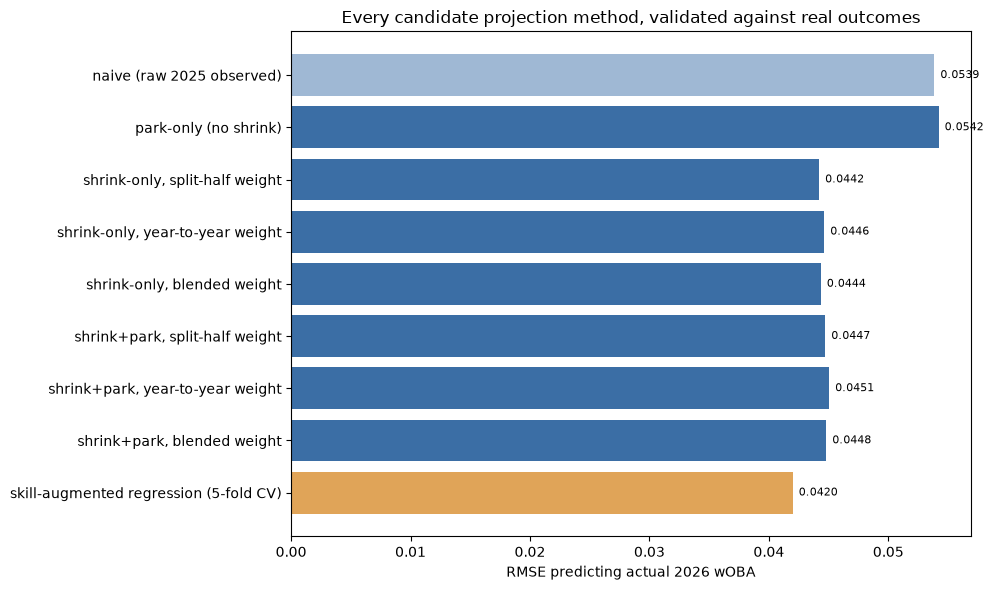

Best method: skill-augmented regression (5-fold CV)  (RMSE=0.0420, +22.0% vs. naive)

Saved -> output/projection_validation_full.csv
Saved -> output/player_projections_all_variants.csv


In [16]:
fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#9fb8d4" if "naive" in i else ("#e0a458" if "regression" in i else "#3b6ea5") for i in results_df.index]
ax.barh(results_df.index[::-1], results_df["RMSE"][::-1], color=colors[::-1])
for i, v in enumerate(results_df["RMSE"][::-1]):
    ax.text(v + 0.0005, i, f"{v:.4f}", va="center", fontsize=8)
ax.set_xlabel("RMSE predicting actual 2026 wOBA")
ax.set_title("Every candidate projection method, validated against real outcomes")
plt.tight_layout()
plt.savefig("output/projection_full_validation.png", dpi=150)
plt.show()

best = results_df["RMSE"].idxmin()
print(f"Best method: {best}  (RMSE={results_df.loc[best,'RMSE']:.4f}, "
      f"{results_df.loc[best,'pct_improvement_vs_naive']:+.1f}% vs. naive)")

pairs.to_csv("output/projection_validation_full.csv", index=False)
comp.to_csv("output/player_projections_all_variants.csv", index=False)
print("\nSaved -> output/projection_validation_full.csv")
print("Saved -> output/player_projections_all_variants.csv")


---
## 14. Sample-size-aware shrinkage: give every player their own personal weight

Every candidate so far shrinks all players in a component by the *same*
amount, whether they have 60 PA or 450. Real empirical Bayes shrinkage
should weight each player by their own sample size: `r(n) = n / (n + k)`,
where `k` is a per-component constant (the sample size at which reliability
hits 0.5).

**Two ways to estimate k, tested rather than assumed:**
- Fitting `k` from reliability measured at several PA thresholds (30, 50,
  75...300) hits a real problem: requiring a higher PA floor selects a
  smaller, more homogeneous "everyday player" population, which mechanically
  *shrinks* the between-player variance the reliability calculation depends
  on -- BB's empirical curve actually reliability peaks at n=150 (.898) and
  then *falls* to .771 at n=300, violating the monotonic formula. That's a
  restriction-of-range artifact, not a real effect.
- The cleaner fix: estimate the population's true-talent variance directly
  from **one fixed population** (no shifting-threshold confound) by
  subtracting expected binomial sampling noise from observed variance, then
  solve for k analytically.


In [17]:
SAMPLESIZE_MIN_PA = 30

pop_rows = []
for (bid, yr), g in woba_pa.groupby(["batter_id", "year"]):
    if len(g) < SAMPLESIZE_MIN_PA:
        continue
    row = {"batter_id": bid, "year": yr, "n": len(g)}
    for name in ["BB", "HBP", "K", "1B", "2B", "3B", "HR"]:
        col, fn = {
            "BB": ("k_or_bb", lambda s: (s == "walk").astype(float)),
            "HBP": ("pitch_call", lambda s: (s == "hit_by_pitch").astype(float)),
            "K": ("k_or_bb", lambda s: (s == "strikeout").astype(float)),
            "1B": ("play_result", lambda s: (s == "single").astype(float)),
            "2B": ("play_result", lambda s: (s == "double").astype(float)),
            "3B": ("play_result", lambda s: (s == "triple").astype(float)),
            "HR": ("play_result", lambda s: (s == "home_run").astype(float)),
        }[name]
        row[f"{name}_rate"] = fn(g[col]).mean()
    pop_rows.append(row)
pop_df = pd.DataFrame(pop_rows)
print(f"fixed population for k-fitting: {len(pop_df)} batter-seasons, n >= {SAMPLESIZE_MIN_PA}")

k_analytical = {}
for name in ["BB", "HBP", "K", "1B", "2B", "3B", "HR"]:
    p_bar = pop_df[f"{name}_rate"].mean()
    observed_var = pop_df[f"{name}_rate"].var(ddof=1)
    expected_noise_var = (p_bar * (1 - p_bar) / pop_df["n"]).mean()
    true_var = max(observed_var - expected_noise_var, 1e-8)
    k = p_bar * (1 - p_bar) / true_var
    k_analytical[name] = k
    print(f"  {name}: p_bar={p_bar:.4f}  k={k:.1f}  ->  r(60)={60/(60+k):.3f}  r(150)={150/(150+k):.3f}  r(300)={300/(300+k):.3f}")


fixed population for k-fitting: 599 batter-seasons, n >= 30
  BB: p_bar=0.1076  k=90.8  ->  r(60)=0.398  r(150)=0.623  r(300)=0.768
  HBP: p_bar=0.0237  k=87.8  ->  r(60)=0.406  r(150)=0.631  r(300)=0.774
  K: p_bar=0.2058  k=40.1  ->  r(60)=0.599  r(150)=0.789  r(300)=0.882
  1B: p_bar=0.1570  k=187.9  ->  r(60)=0.242  r(150)=0.444  r(300)=0.615
  2B: p_bar=0.0400  k=649.8  ->  r(60)=0.085  r(150)=0.188  r(300)=0.316
  3B: p_bar=0.0032  k=319025.8  ->  r(60)=0.000  r(150)=0.000  r(300)=0.001
  HR: p_bar=0.0212  k=147.6  ->  r(60)=0.289  r(150)=0.504  r(300)=0.670


3B's k blows up (near-zero true variance detected for a very rare event
-- numerically unstable, not a meaningful "zero skill" claim), so its
personalized weight gets the same safety clip used everywhere else in this
notebook.


In [18]:
SHRINK_MIN, SHRINK_MAX = 0.05, 0.95

def personal_weight(n, comp_name):
    k = k_analytical[comp_name]
    return np.clip(n / (n + k), SHRINK_MIN, SHRINK_MAX)

for k_ in ["BB", "HBP", "1B", "2B", "3B", "HR"]:
    comp[f"{k_}_weight_samplesize"] = personal_weight(comp["PA"], k_)
    src_col = f"{k_}_rate_neutral" if k_ in ["1B", "2B", "3B", "HR"] else f"{k_}_rate"
    comp[f"{k_}_shrunk_samplesize"] = league_means[k_] + comp[f"{k_}_weight_samplesize"] * (comp[src_col] - league_means[k_])
    comp[f"{k_}_shrunk_raw_samplesize"] = league_means[k_] + comp[f"{k_}_weight_samplesize"] * (comp[f"{k_}_rate"] - league_means[k_])

comp["woba_proj_samplesize"] = sum(comp[f"{k_}_shrunk_samplesize"] * WOBA_WEIGHTS[k_] for k_ in ["BB", "HBP", "1B", "2B", "3B", "HR"])
comp["woba_proj_shrinkonly_samplesize"] = sum(comp[f"{k_}_shrunk_raw_samplesize"] * WOBA_WEIGHTS[k_] for k_ in ["BB", "HBP", "1B", "2B", "3B", "HR"])

print(f"Weight range actually applied (BB, across real PA counts in the data):")
print(comp[["PA", "BB_weight_samplesize"]].describe().round(3))


Weight range actually applied (BB, across real PA counts in the data):
            PA  BB_weight_samplesize
count 514.0000              514.0000
mean  227.0820                0.6750
std   106.3980                0.1230
min    60.0000                0.3980
25%   126.0000                0.5810
50%   227.0000                0.7140
75%   317.7500                0.7780
max   452.0000                0.8330


## 15. Add sample-size-aware variants to the full validation

In [19]:
pairs2 = comp[comp["year"] == 2025].merge(
    comp[comp["year"] == 2026][["batter_id", "obs_woba"]].rename(columns={"obs_woba": "actual_2026_woba"}),
    on="batter_id", how="inner",
).merge(reg_data[["batter_id", "woba_proj_regression_cv"]], on="batter_id", how="left")

candidates2 = dict(candidates)
candidates2["shrink-only, sample-size-aware"] = "woba_proj_shrinkonly_samplesize"
candidates2["shrink+park, sample-size-aware"] = "woba_proj_samplesize"

rows2 = []
for label, col in candidates2.items():
    sub = pairs2.dropna(subset=[col, "actual_2026_woba"])
    rmse = np.sqrt(((sub[col] - sub["actual_2026_woba"]) ** 2).mean())
    r, _ = pearsonr(sub[col], sub["actual_2026_woba"])
    rows2.append({"method": label, "n": len(sub), "RMSE": rmse, "corr": r})

results_df2 = pd.DataFrame(rows2).set_index("method")
naive_rmse2 = results_df2.loc["naive (raw 2025 observed)", "RMSE"]
results_df2["pct_improvement_vs_naive"] = (naive_rmse2 - results_df2["RMSE"]) / naive_rmse2 * 100
results_df2.sort_values("RMSE").round(4)


,n,RMSE,corr,pct_improvement_vs_naive
method,,,,
skill-augmented regression (5-fold CV),108,0.0420,0.4293,22.0150
"shrink-only, split-half weight",108,0.0442,0.3924,17.9095
"shrink-only, blended weight",108,0.0444,0.3958,17.6511
"shrink-only, sample-size-aware",108,0.0446,0.3933,17.1382
"shrink-only, year-to-year weight",108,0.0446,0.3971,17.1162
"shrink+park, split-half weight",108,0.0447,0.3662,16.9552
"shrink+park, blended weight",108,0.0448,0.3721,16.8006
"shrink+park, year-to-year weight",108,0.0451,0.3752,16.3513
"shrink+park, sample-size-aware",108,0.0452,0.3648,16.1390


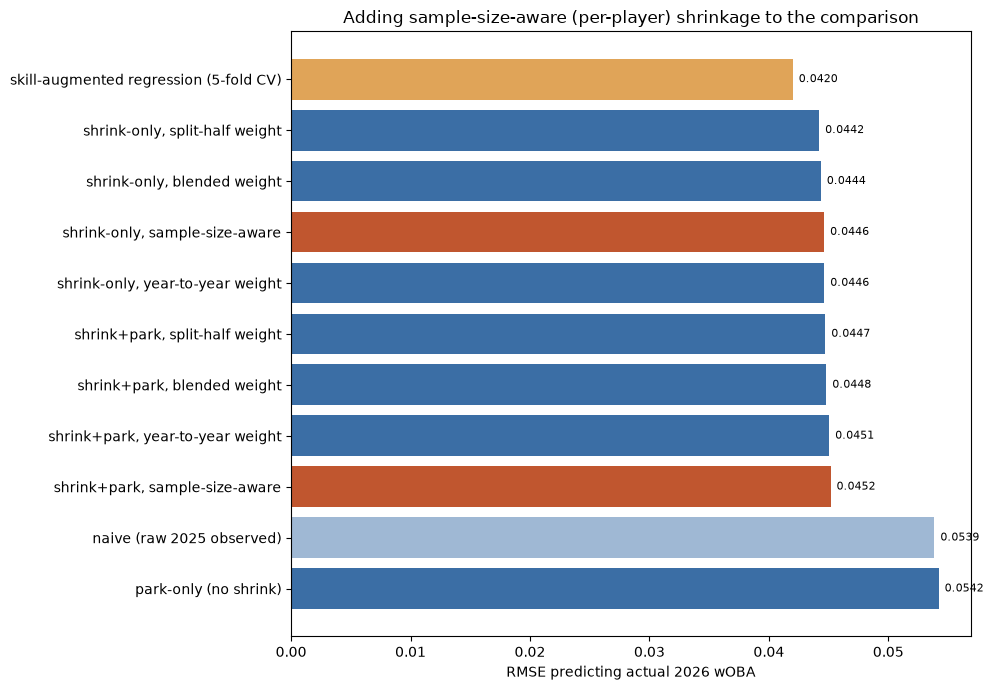

Best method: skill-augmented regression (5-fold CV)  (RMSE=0.0420, +22.0% vs. naive)

Saved (updated) -> output/player_projections_all_variants.csv, output/projection_validation_full.csv


In [20]:
fig, ax = plt.subplots(figsize=(10, 7))
sorted_res = results_df2.sort_values("RMSE", ascending=False)
colors = ["#9fb8d4" if "naive" in i else ("#e0a458" if "regression" in i else ("#c0562f" if "sample-size" in i else "#3b6ea5")) for i in sorted_res.index]
ax.barh(sorted_res.index, sorted_res["RMSE"], color=colors)
for i, v in enumerate(sorted_res["RMSE"]):
    ax.text(v + 0.0005, i, f"{v:.4f}", va="center", fontsize=8)
ax.set_xlabel("RMSE predicting actual 2026 wOBA")
ax.set_title("Adding sample-size-aware (per-player) shrinkage to the comparison")
plt.tight_layout()
plt.savefig("output/projection_validation_with_samplesize.png", dpi=150)
plt.show()

best2 = results_df2["RMSE"].idxmin()
print(f"Best method: {best2}  (RMSE={results_df2.loc[best2,'RMSE']:.4f}, {results_df2.loc[best2,'pct_improvement_vs_naive']:+.1f}% vs. naive)")

comp.to_csv("output/player_projections_all_variants.csv", index=False)
pairs2.to_csv("output/projection_validation_full.csv", index=False)
print("\nSaved (updated) -> output/player_projections_all_variants.csv, output/projection_validation_full.csv")


---
## 16. Tested and rejected: adding xBA/xwOBA to reduce noise

Motivation: BABIP-driven components (1B/2B/3B rates) mix real contact-quality
skill with pure luck (was a well-struck ball fielded or not?). The league's
own contact-quality-based expected stats (`xba`, `xwoba` -- built at the very
start of this whole project) seemed like a natural way to separate the two.

**Against the bare shrunk-components baseline (no skill metrics), adding
avg xwOBA helped a little**: RMSE .0433 -> .0430. The idea has real merit.

**But against the actual best model (skill-augmented regression, which
already includes Barrel%/EV90/PullAir%/GB%/Whiff%), adding xBA/xwOBA does
nothing**: RMSE .0420 -> .0418-.0422 (within 5-fold CV noise on 108
samples, not a real improvement in either direction). The reason: xwOBA/xBA
are themselves computed from exit velocity and launch angle -- the same raw
inputs Barrel% and EV90 already capture directly. Once those are in the
model, the "expected stat" version is a repackaging of information already
present, not new information.

**Conclusion:** the underlying idea (contact-quality-based de-noising) is
sound and already fully captured via Barrel%/EV90 -- no further gain
available from this specific angle. Standing best model remains the skill-
augmented regression at RMSE=.0420 (+22.0% vs. naive).


---
## 17. GB% split by direction: OppoGB% vs. PullGB%

Tested replacing plain GB% with direction-specific splits, since we already
know direction carries real value information (Pull/Air quadrant work
earlier this session).

| Feature set | RMSE |
|---|---|
| GB% (baseline) | .0420 |
| OppoGB% (swap) | .0420 |
| **PullGB% (swap)** | **.0417** |
| GB% + OppoGB% (both) | .0424 (worse) |

**OppoGB% doesn't help**, despite a *stronger* raw bivariate correlation
with 2026 wOBA than plain GB% (-.169 vs -.142) -- once PullAir%/Barrel%/EV90
are already in the model, OppoGB%'s signal is largely redundant with what
those capture (not pulling it in the air mechanically correlates with
hitting it the other way on the ground).

**PullGB% gives a small, mechanistically sensible improvement**: a pulled
ground ball is close to a universal weak-contact signature (rolled over,
out in front), more specific than a generic grounder rate. Real gain, but
modest (~0.7% relative) on a 108-pair validation sample -- worth adopting
as the new default over plain GB%, not worth over-claiming as decisive.


In [21]:
bbe["is_pull_gb"] = ((bbe["angle"] < 10) & (bbe["spray_pull"] > 15)).astype(float)

def skill_rates_bbe_v2(g):
    return pd.Series({"n_bbe": len(g), "Barrel_pct": g["barrel_f"].mean(), "EV90": g["exit_speed"].quantile(0.90),
                       "PullAir_pct": g["is_pullair"].mean(), "PullGB_pct": g["is_pull_gb"].mean()})

skill_bbe_v2 = bbe.groupby(["batter_id", "year"]).apply(skill_rates_bbe_v2, include_groups=False).reset_index()
skill_bbe_v2 = skill_bbe_v2[skill_bbe_v2["n_bbe"] >= MIN_SKILL_BBE]
skills_v2 = skill_bbe_v2.merge(skill_whiff, on=["batter_id", "year"])

reg_data_v2 = comp[comp["year"] == 2025].merge(
    comp[comp["year"] == 2026][["batter_id", "obs_woba"]].rename(columns={"obs_woba": "actual_2026_woba"}),
    on="batter_id", how="inner",
).merge(skills_v2[skills_v2["year"] == 2025].drop(columns=["year"]), on="batter_id", how="inner")

feature_cols_v2 = ["woba_proj_blended", "Barrel_pct", "EV90", "PullAir_pct", "PullGB_pct", "Whiff_pct"]
X_v2 = reg_data_v2[feature_cols_v2].to_numpy()
y_v2 = reg_data_v2["actual_2026_woba"].to_numpy()
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_preds_v2 = np.zeros(len(reg_data_v2))
for tr_idx, te_idx in kf.split(X_v2):
    m = LinearRegression().fit(X_v2[tr_idx], y_v2[tr_idx])
    cv_preds_v2[te_idx] = m.predict(X_v2[te_idx])
rmse_v2 = np.sqrt(((cv_preds_v2 - y_v2) ** 2).mean())
print(f"5-fold CV RMSE with PullGB% replacing GB%: {rmse_v2:.4f}  (was {rmse_reg:.4f} with plain GB%)")

reg_data_v2["woba_proj_regression_v2"] = cv_preds_v2
reg_data_v2.to_csv("output/player_projections_pullgb_variant.csv", index=False)
print("Saved -> output/player_projections_pullgb_variant.csv")


5-fold CV RMSE with PullGB% replacing GB%: 0.0417  (was 0.0420 with plain GB%)
Saved -> output/player_projections_pullgb_variant.csv
